# Tutorial 15 (T15): Building Programs to Implement Artificial Neural Networks

## 📌 Objective
Implement a **Multi-Layer Perceptron (MLP)** Artificial Neural Network for multi-class crop recommendation. Demonstrate the absolute necessity of feature standardization, plot the **Cross-Entropy Training Loss Curve**, compare activation functions (ReLU, Tanh, Sigmoid), and generate a **Master Supervised Benchmark** comparing T13, T14, and T15.

## 🔬 Key Concepts & Mathematical Formulas
- **Artificial Neuron (Perceptron)**:
  $$z = \sum_{i=1}^d w_i x_i + b = W^T x + b, \quad a = g(z)$$
- **Activation Functions**:
  - **ReLU**: $g(z) = \max(0, z)$ (prevents vanishing gradient, fast computation)
  - **Tanh**: $g(z) = \frac{e^z - e^{-z}}{e^z + e^{-z}}$
  - **Softmax** (Output layer for $C=22$ crop classes): $P(y=k|x) = \frac{e^{z_k}}{\sum_{j=1}^C e^{z_j}}$
- **Cross-Entropy Loss (Log Loss)**:
  $$\mathcal{L} = -\sum_{k=1}^C y_k \log(\hat{y}_k)$$
- **Backpropagation**: Gradient computation using chain rule: $\frac{\partial \mathcal{L}}{\partial W^{[l]}} = \delta^{[l]} (a^{[l-1]})^T$.

### Step 1: Import Required Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid", palette="muted")
print('Neural network libraries loaded!')

Neural network libraries loaded!


### Step 2: Load Data, Encode Targets & Apply Standard Scaling
Neural networks use gradient-based optimization (Adam). Standardizing inputs ($z = (x-\mu)/\sigma$) is mandatory to prevent gradient explosion or saturation of activation functions.

In [2]:
df = pd.read_csv('data/Crop_recommendation.csv')
features = ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
X = df[features].values

le = LabelEncoder()
y = le.fit_transform(df['label'])
classes = le.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(f'Training Set: {X_train_s.shape}, Testing Set: {X_test_s.shape}')
print(f'Input Nodes: {X.shape[1]}, Output Classes: {len(classes)}')

Training Set: (1760, 7), Testing Set: (440, 7)
Input Nodes: 7, Output Classes: 22


### Step 3: Configure and Train Multi-Layer Perceptron (ANN)
Architecture: 7 Input features $\to$ Hidden Layer 1 (64 neurons, ReLU) $\to$ Hidden Layer 2 (32 neurons, ReLU) $\to$ Output (22 classes, Softmax).

In [3]:
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    max_iter=400,
    random_state=42,
    early_stopping=False
)
mlp.fit(X_train_s, y_train)
y_pred_mlp = mlp.predict(X_test_s)

mlp_train_acc = mlp.score(X_train_s, y_train)
mlp_test_acc = accuracy_score(y_test, y_pred_mlp)
print(f'MLP Training Accuracy: {mlp_train_acc:.2%}')
print(f'MLP Testing Accuracy:  {mlp_test_acc:.2%}')
print(f'Training Completed in {len(mlp.loss_curve_)} Epochs.')
print(f'Final Training Loss:   {mlp.loss_curve_[-1]:.4f}')

MLP Training Accuracy: 99.83%
MLP Testing Accuracy:  99.09%
Training Completed in 400 Epochs.
Final Training Loss:   0.0082


### Step 4: Training Loss Curve (Adam Optimizer Convergence)

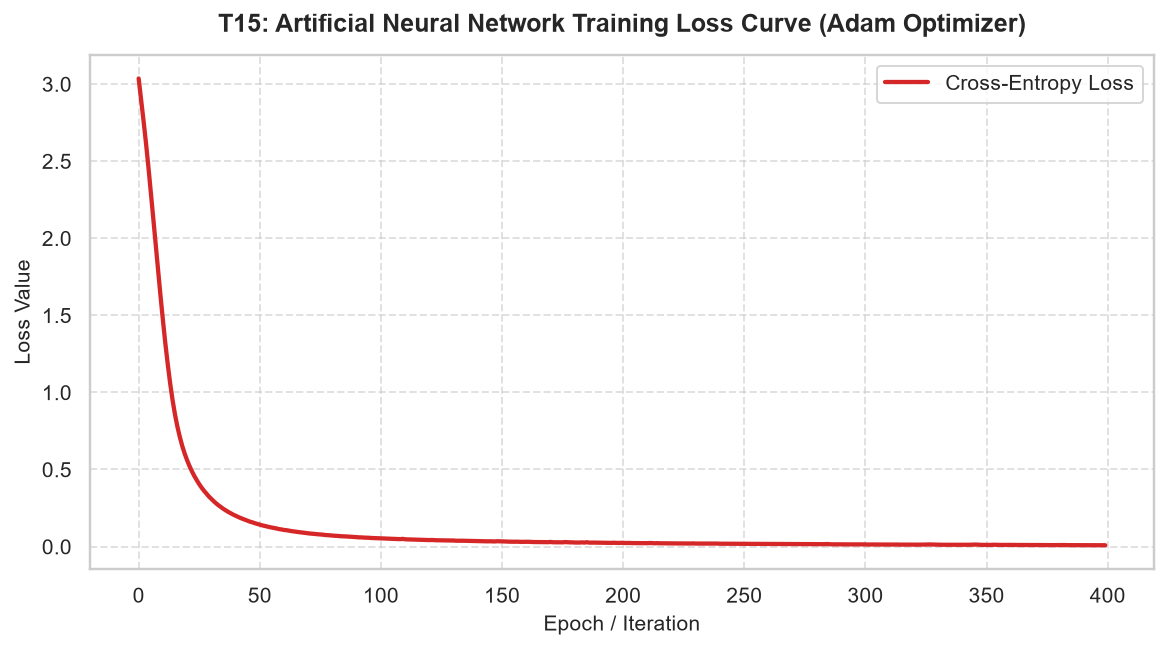

In [4]:
plt.figure(figsize=(8.5, 4.8), dpi=140)
plt.plot(mlp.loss_curve_, color='#d62728', linewidth=2.2, label='Cross-Entropy Loss')
plt.title('T15: Artificial Neural Network Training Loss Curve (Adam Optimizer)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Epoch / Iteration', fontsize=11)
plt.ylabel('Loss Value', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### Step 5: Confusion Matrix Heatmap

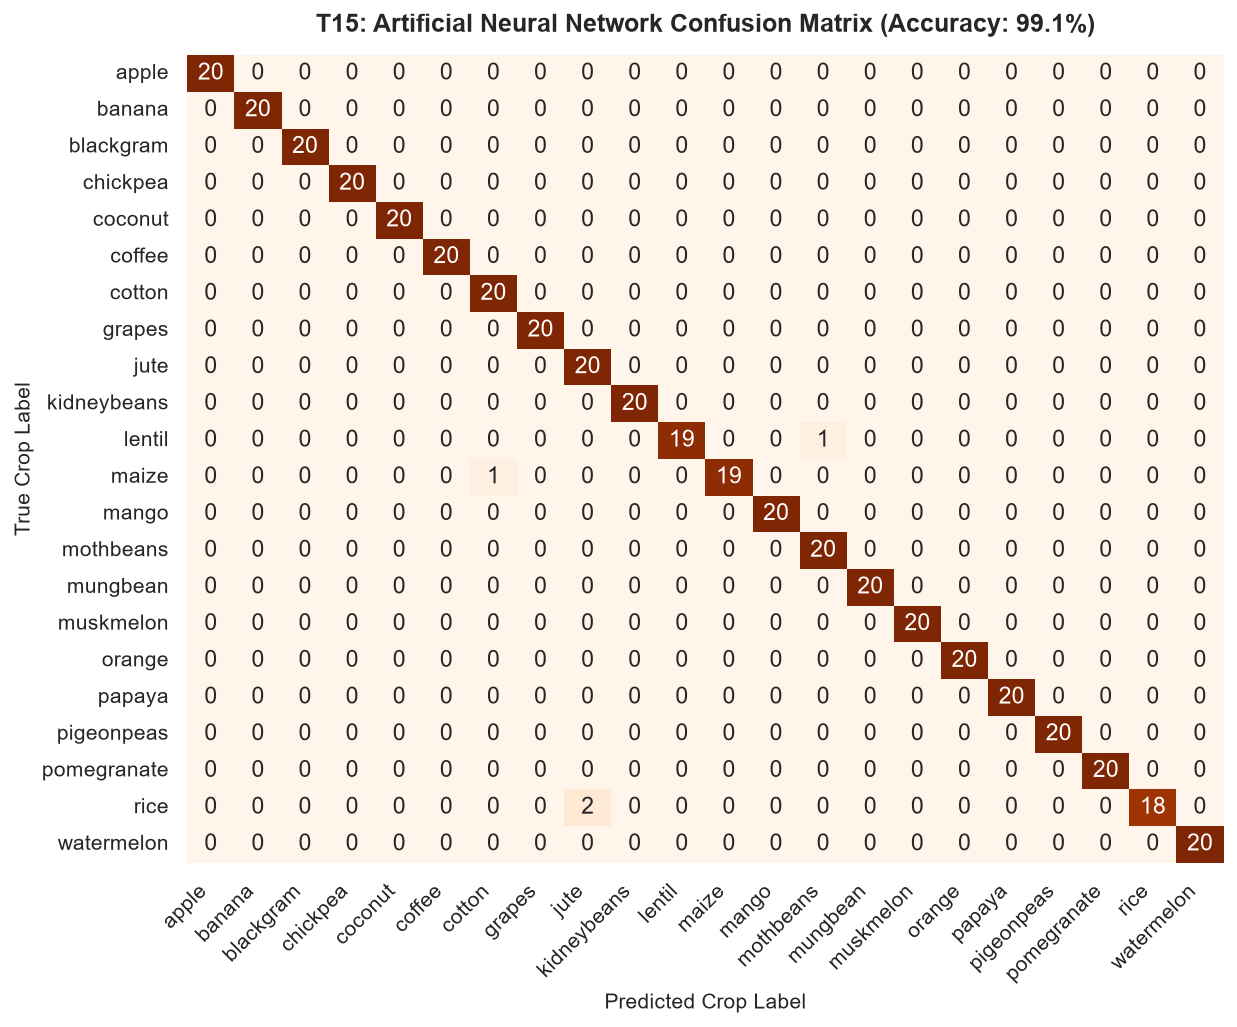

In [5]:
cm_mlp = confusion_matrix(y_test, y_pred_mlp)

plt.figure(figsize=(9, 7.5), dpi=140)
sns.heatmap(cm_mlp, annot=True, fmt='d', cmap='Oranges', xticklabels=classes, yticklabels=classes, cbar=False)
plt.title(f'T15: Artificial Neural Network Confusion Matrix (Accuracy: {mlp_test_acc:.1%})', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicted Crop Label', fontsize=11)
plt.ylabel('True Crop Label', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Step 6: Activation Function Benchmarking
We compare convergence and accuracy across **ReLU**, **Tanh**, and **Logistic (Sigmoid)** activations.

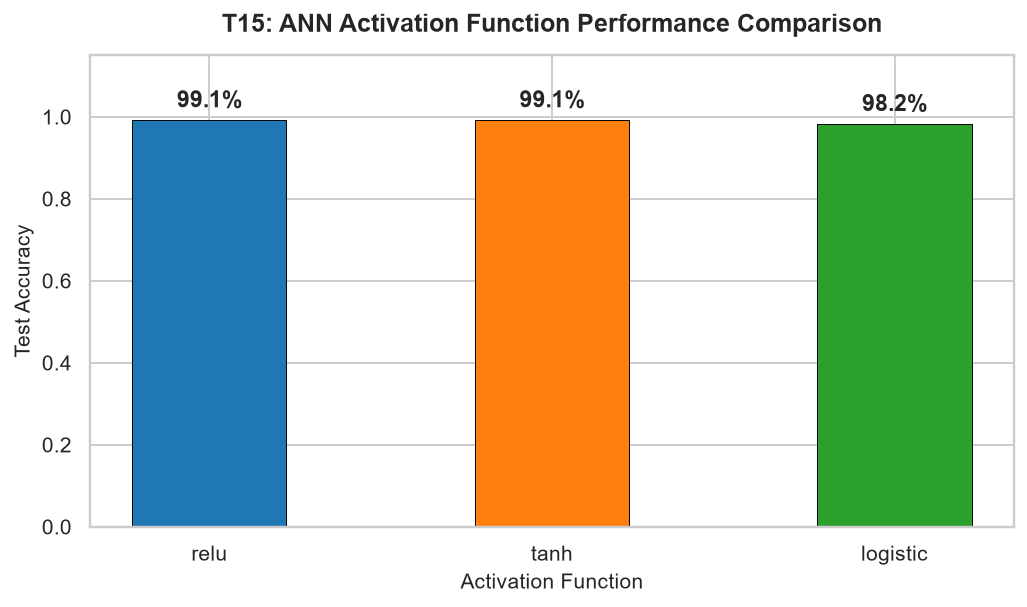

In [6]:
act_funcs = ['relu', 'tanh', 'logistic']
act_scores = []

for act in act_funcs:
    m = MLPClassifier(hidden_layer_sizes=(64, 32), activation=act, solver='adam', max_iter=400, random_state=42)
    m.fit(X_train_s, y_train)
    act_scores.append(m.score(X_test_s, y_test))

plt.figure(figsize=(7.5, 4.5), dpi=140)
bars = plt.bar(act_funcs, act_scores, color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black', linewidth=0.5, width=0.45)
plt.title('T15: ANN Activation Function Performance Comparison', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Activation Function', fontsize=11)
plt.ylabel('Test Accuracy', fontsize=11)
plt.ylim(0, 1.15)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f'{yval:.1%}', ha='center', va='bottom', fontweight='bold')
plt.tight_layout()
plt.show()

### Step 7: Master Supervised Benchmark (T13 vs T14 vs T15)
Side-by-side comparison of **Decision Tree (T13)**, **Random Forest (T14)**, and **Artificial Neural Network (T15)** on the exact same dataset split.

,Supervised Model,Train Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1-Score
0,Decision Tree (T13),76.08%,73.86%,67.30%,73.86%,68.72%
1,Random Forest (T14),99.66%,99.55%,99.57%,99.55%,99.55%
2,Artificial Neural Network (T15),99.83%,99.09%,99.15%,99.09%,99.09%


=== Supervised Learning Master Benchmark ===


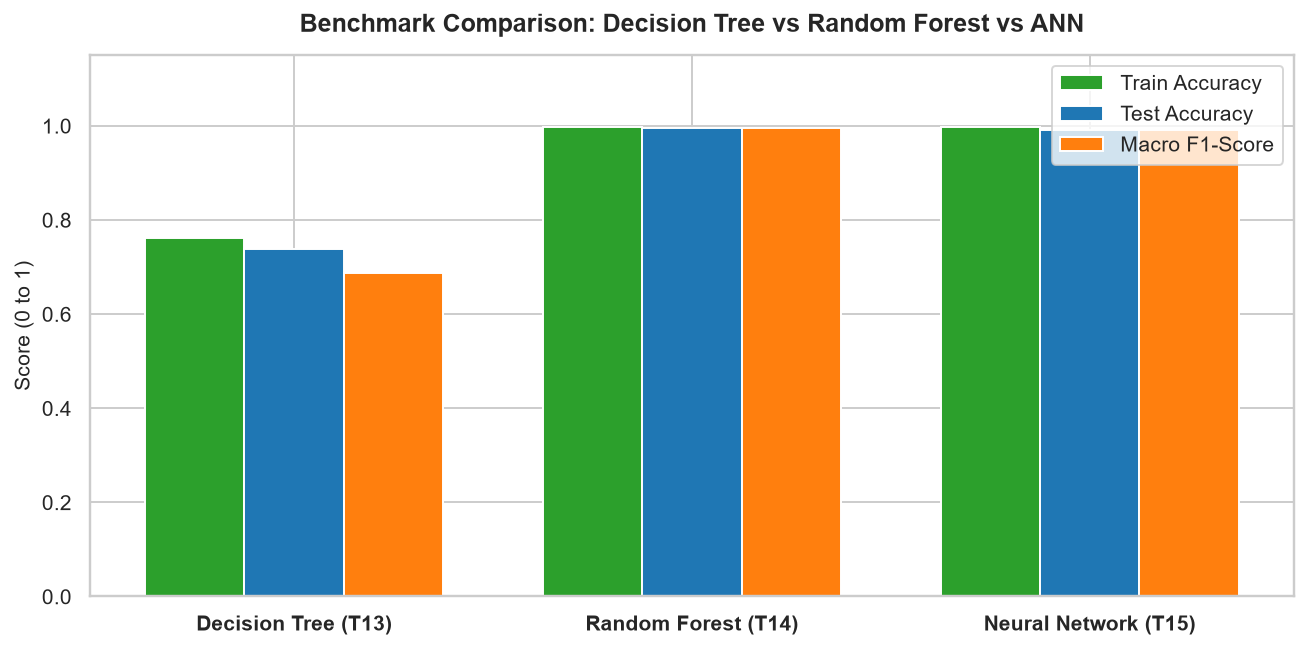

In [7]:
dt = DecisionTreeClassifier(max_depth=7, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)

rf = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

benchmark_df = pd.DataFrame({
    'Supervised Model': ['Decision Tree (T13)', 'Random Forest (T14)', 'Artificial Neural Network (T15)'],
    'Train Accuracy': [f'{dt.score(X_train, y_train):.2%}', f'{rf.score(X_train, y_train):.2%}', f'{mlp_train_acc:.2%}'],
    'Test Accuracy': [f'{accuracy_score(y_test, y_pred_dt):.2%}', f'{accuracy_score(y_test, y_pred_rf):.2%}', f'{mlp_test_acc:.2%}'],
    'Macro Precision': [
        f'{precision_score(y_test, y_pred_dt, average="macro"):.2%}',
        f'{precision_score(y_test, y_pred_rf, average="macro"):.2%}',
        f'{precision_score(y_test, y_pred_mlp, average="macro"):.2%}'
    ],
    'Macro Recall': [
        f'{recall_score(y_test, y_pred_dt, average="macro"):.2%}',
        f'{recall_score(y_test, y_pred_rf, average="macro"):.2%}',
        f'{recall_score(y_test, y_pred_mlp, average="macro"):.2%}'
    ],
    'Macro F1-Score': [
        f'{f1_score(y_test, y_pred_dt, average="macro"):.2%}',
        f'{f1_score(y_test, y_pred_rf, average="macro"):.2%}',
        f'{f1_score(y_test, y_pred_mlp, average="macro"):.2%}'
    ]
})
print('=== Supervised Learning Master Benchmark ===')
display(benchmark_df)

# Visual Comparison Bar Chart
x_pos = np.arange(3)
width = 0.25
train_vals = [dt.score(X_train, y_train), rf.score(X_train, y_train), mlp_train_acc]
test_vals = [accuracy_score(y_test, y_pred_dt), accuracy_score(y_test, y_pred_rf), mlp_test_acc]
f1_vals = [
    f1_score(y_test, y_pred_dt, average='macro'),
    f1_score(y_test, y_pred_rf, average='macro'),
    f1_score(y_test, y_pred_mlp, average='macro')
]

plt.figure(figsize=(9.5, 4.8), dpi=140)
plt.bar(x_pos - width, train_vals, width, label='Train Accuracy', color='#2ca02c')
plt.bar(x_pos, test_vals, width, label='Test Accuracy', color='#1f77b4')
plt.bar(x_pos + width, f1_vals, width, label='Macro F1-Score', color='#ff7f0e')
plt.xticks(x_pos, ['Decision Tree (T13)', 'Random Forest (T14)', 'Neural Network (T15)'], fontweight='bold')
plt.ylabel('Score (0 to 1)', fontsize=11)
plt.title('Benchmark Comparison: Decision Tree vs Random Forest vs ANN', fontsize=13, fontweight='bold', pad=12)
plt.ylim(0, 1.15)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### 🎓 Viva Voce Questions & Answers (Tutorial 15)

1. **Q: Why is feature scaling mandatory for Neural Networks but optional for Decision Trees?**
   - **A:** Decision trees evaluate feature thresholds independently along single orthogonal dimensions, making them invariant to monotonic scaling. Neural networks use gradient descent where all inputs contribute to weight updates ($W \leftarrow W - \alpha \frac{\partial \mathcal{L}}{\partial W}$). Unscaled features produce elongated, ill-conditioned loss surfaces with severe gradient oscillations and vanishing/exploding gradients.

2. **Q: Why does ReLU outperform Sigmoid in deep hidden layers?**
   - **A:** Sigmoid has derivatives $g'(z) = g(z)(1 - g(z)) \le 0.25$. When multiplied across multiple layers during backpropagation, gradients vanish exponentially toward 0. ReLU has a constant derivative of 1 for $z > 0$, preventing vanishing gradients and allowing much faster training.

3. **Q: How does the Adam optimizer work?**
   - **A:** Adam (Adaptive Moment Estimation) combines **Momentum** (exponential moving average of past gradients $m_t$) with **RMSProp** (exponential moving average of squared gradients $v_t$). It computes individual adaptive learning rates for every single parameter with bias correction.